# 3. Coordinates, geometry, and trustworthy joins

**Question:** Which sensors fall inside a service area, and what does distance mean?
**Objectives:** audit keys, distinguish a CRS assignment from a transformation, validate geometry,
and compare a point-in-polygon result with a known answer. **Time:** 35 minutes.

A fictional 4 km by 3 km rectangle contains three instruments and excludes one.
First solve in an explicitly local plane. Then use `sf` on synthetic projected coordinates.
[Open in Lab](https://jltobias.github.io/JupyterLite-R/lite/lab/index.html?path=03-vector-geometry.ipynb)

  id    x    y inside
1  A  500  500   TRUE
2  B 1500 2500   TRUE
3  C 3500 1500   TRUE
4  D 4500 1500  FALSE


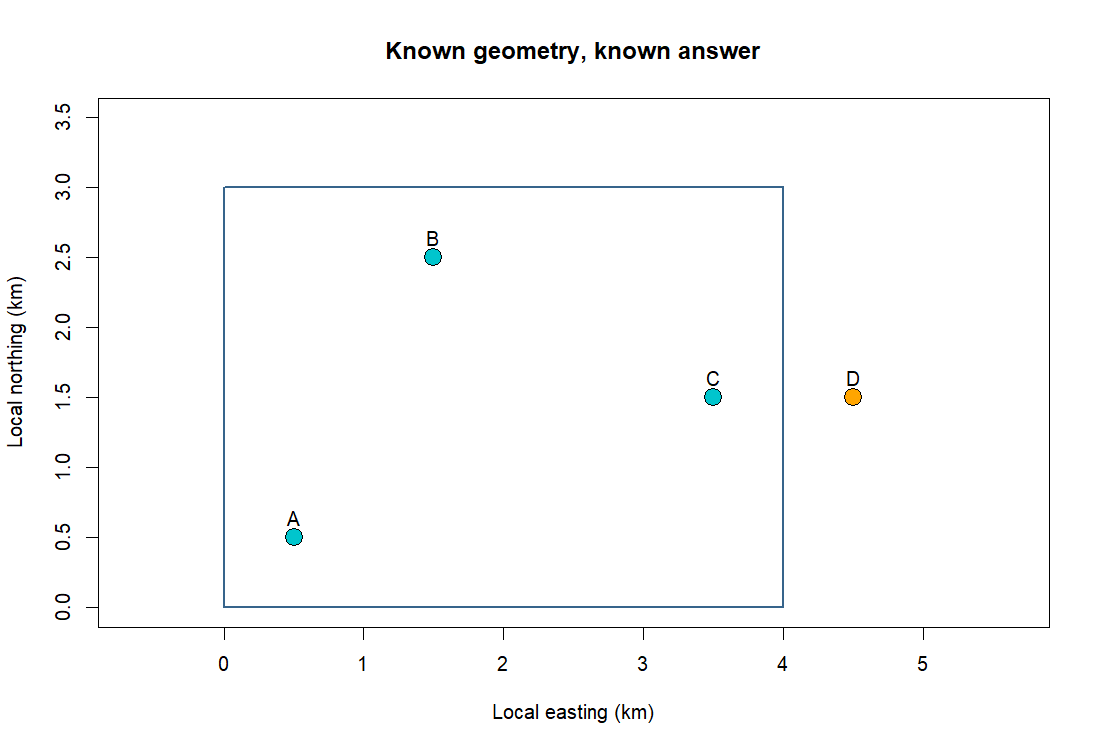

In [1]:
# Project: JupyterLite-R | Chapter 03 | Inputs: synthetic coordinates.
# Author: project contributors with Codex | Contact: repository Issues.
# Created/updated: 2026-11-16 | Outputs: geometry map and audited membership.
# Dependencies: base R; optional sf. Change log: initial lesson.
sensors <- data.frame(id = c("A", "B", "C", "D"), x = c(500, 1500, 3500, 4500),
                      y = c(500, 2500, 1500, 1500))
stopifnot(!anyDuplicated(sensors$id))
sensors$inside <- with(sensors, x > 0 & x < 4000 & y > 0 & y < 3000)
stopifnot(identical(sensors$inside, c(TRUE, TRUE, TRUE, FALSE)))
plot(sensors$x / 1000, sensors$y / 1000, xlim = c(0, 5), ylim = c(0, 3.5),
     asp = 1, pch = 21, bg = ifelse(sensors$inside, "turquoise3", "orange"), cex = 2,
     xlab = "Local easting (km)", ylab = "Local northing (km)", main = "Known geometry, known answer")
rect(0, 0, 4, 3, border = "steelblue4", lwd = 2)
text(sensors$x / 1000, sensors$y / 1000, sensors$id, pos = 3)
print(sensors)

## Extension: simple features with sf
Install deliberately with `webr::install("sf")`. If unavailable, run this extension in desktop R.
We locate invented points within UTM zone 18N **for the projection exercise only**. The offset
gives plausible projected coordinates; it does not assert that these are observed locations.
`st_as_sf(..., crs=32618)` assigns the known coordinate system. `st_transform(..., 4326)`
actually computes new longitude/latitude coordinates. Relabelling metres as degrees is wrong.

In [ ]:
if (requireNamespace("sf", quietly = TRUE)) {
  projected <- transform(sensors, x = x + 500000, y = y + 4400000)
  points_sf <- sf::st_as_sf(projected, coords = c("x", "y"), crs = 32618)
  corners <- rbind(c(500000,4400000), c(504000,4400000), c(504000,4403000),
                   c(500000,4403000), c(500000,4400000))
  area_sf <- sf::st_sfc(sf::st_polygon(list(corners)), crs = 32618)
  stopifnot(all(sf::st_is_valid(area_sf)), all(sf::st_is_valid(points_sf)))
  membership <- lengths(sf::st_within(points_sf, area_sf)) > 0
  stopifnot(identical(membership, sensors$inside),
            abs(as.numeric(sf::st_area(area_sf)) - 12000000) < .01)
  lonlat <- sf::st_transform(points_sf, 4326)
  recovered <- sf::st_transform(lonlat, 32618)
  stopifnot(max(abs(sf::st_coordinates(recovered) - sf::st_coordinates(points_sf))) < .01)
  print(lonlat)
  print(sf::st_distance(points_sf[1, ], points_sf[2, ]))
  print(sf::sf_extSoftVersion())
} else message("Optional sf extension skipped: package not installed. Core geometry checks passed independently.")

## A shuffled attribute table is not a spatial join
Attributes must be matched by unique identifiers, not by row position. A geometry engine
cannot repair an incorrect table join. Our join stops on duplicate or missing IDs.

In [2]:
attributes <- data.frame(id = c("D", "B", "A", "C"), reading = c(7, 11, 9, 13))
stopifnot(!anyDuplicated(attributes$id), setequal(sensors$id, attributes$id))
idx <- match(sensors$id, attributes$id)
stopifnot(!anyNA(idx))
sensors$reading <- attributes$reading[idx]
stopifnot(sensors$reading[sensors$id == "A"] == 9)
print(sensors)

  id    x    y inside reading
1  A  500  500   TRUE       9
2  B 1500 2500   TRUE      11
3  C 3500 1500   TRUE      13
4  D 4500 1500  FALSE       7


## Practice and check
1. Put a point exactly on the border. Compare `st_within` and `st_intersects` and state your rule.
2. Add a duplicate attribute ID and confirm that the assertion catches it.
3. Explain why an area of 12,000,000 means square metres here, not square kilometres.
**Checkpoint:** three points are strictly inside; A joins to 9; the area is 12 square kilometres.

## Sources
[sf geometry constructors](https://r-spatial.github.io/sf/reference/st.html);
[sf transformations](https://r-spatial.github.io/sf/reference/st_transform.html);
[Pebesma (2018), Simple Features for R](https://doi.org/10.32614/RJ-2018-009).